<a href="https://colab.research.google.com/github/jkf87/jev-handson/blob/main/04_CCTV%EC%83%81%ED%83%9C%ED%8C%90%EB%8B%A8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/jkf87/jev-handson/blob/main/04_CCTV%EC%83%81%ED%83%9C%ED%8C%90%EB%8B%A8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CCTV 영상을 보고 상태 판단하기: 동영상을 받는 Jev류 모델

지금까지는 글(state)만 보냈어요. 이번엔 **CCTV 영상 몇 초를 그대로** 보내고, 글 대신 **보기마다 확률**을 받아요.

| 질문 | 종류 | 무엇을 묻나요 |
|---|---|---|
| `scene` | choice | 지금 무슨 상황인가요? (지나감 · 머무름 · 만남 · **쓰러짐** · **다툼** · **물건 방치** · 사람 없음) |
| `down` | noul | 바닥에 쓰러지거나 주저앉은 사람이 있나요? |
| `staff` | noul | 지금 직원이 가 봐야 하나요? |
| `urgency` | score | 얼마나 급한가요? (조치 없음 → 지켜보기 → 곧 확인 → 즉시 대응) |

- 모델: [OmniJev/OneJev](https://github.com/OmniJev/OneJev)(Apache-2.0) · 화면 · 사진 · 영상을 받는 오픈 System One 모델이에요. **TypeSafe Jev가 아니에요.**
- 데이터: [CAVIAR](http://homepages.inf.ed.ac.uk/rbf/CAVIAR/)(EC Funded CAVIAR project/IST 2001 37540, CC BY-SA). 건물 로비 천장 카메라, **배우가 연출한 장면**이에요.
- 런타임: **T4 GPU**(런타임 → 런타임 유형 변경). GPU가 없거나 모델이 안 뜨면 강사가 RTX A4000에서 잰 기록으로 같은 그림을 그려요.

> 실제 학교 CCTV는 개인영상정보예요. 수업 · 연구에 쓰려면 목적 외 이용 제한, 비식별, IRB를 먼저 확인하세요. 이 노트북은 공개 연출 데이터만 써요.

## 1. 설정

In [1]:
#@title 무엇으로 돌릴지 고르기
MODEL = "OmniJev/OneJev-0.8B"  #@param ["OmniJev/OneJev-0.8B", "OmniJev/OneJev-4B"]
FORCE_REPLAY = False  #@param {type:"boolean"}
# 0.8B는 약 2.2GB, 4B는 약 10.4GB를 받아요. T4는 bfloat16 연산이 약해서 float16으로 띄워요.

In [2]:
#@title 도우미 준비 (글꼴 · 기록 · 정답)
import os, sys, json, time, glob, subprocess, urllib.request, pathlib, statistics
RAW = "https://raw.githubusercontent.com/jkf87/jev-handson/main/04_cctv"
def fetch_json(name):
    with urllib.request.urlopen(f"{RAW}/{name}", timeout=60) as r:
        return json.load(r)
GT = fetch_json("gt.json")            # 정답 시간축(초): 싸움 · 가방 방치는 CAVIAR XML, 쓰러짐은 강사가 눈으로 붙인 구간
REC = fetch_json("results/cctv-0.8B.json")     # 강사 A4000 기록: OneJev-0.8B float16 (T4에서 돌릴 것과 같은 모델)
REC_BIG = fetch_json("results/cctv-4B.json")    # 비교용: OneJev-4B (시간축은 4개 클립만)
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not glob.glob("/usr/share/fonts/truetype/nanum/NanumGothic.ttf"):
    subprocess.run("apt-get -qq install -y fonts-nanum > /dev/null", shell=True)
import matplotlib, matplotlib.pyplot as plt
from matplotlib import font_manager as fm
for f in glob.glob("/usr/share/fonts/truetype/nanum/*.ttf"):
    fm.fontManager.addfont(f)
plt.rcParams["font.family"] = ["NanumGothic", "Noto Sans CJK KR", "AppleGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("클립", len(GT), "개 · 강사 기록", len(REC["clips"]), "클립")

클립 13 개 · 강사 기록 13 클립


In [3]:
#@title GPU 확인과 실행 모드
import torch
HAS_GPU = torch.cuda.is_available()
MODE = "live" if (HAS_GPU and not FORCE_REPLAY) else "replay"
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "없음", "→ 모드:", MODE)

GPU: Tesla T4 → 모드: live


## 2. CCTV 클립 받기
CAVIAR에서 다섯 개만 받아요(각 6~17MB). 1초에 2장씩 사진으로 잘라 둬요.

In [4]:
CLIPS = ["Walk1", "Rest_FallOnFloor", "Rest_SlumpOnFloor", "Fight_OneManDown", "LeftBag"]
BASE = "https://homepages.inf.ed.ac.uk/rbf/CAVIARDATA1"
os.makedirs("caviar", exist_ok=True)
for n in CLIPS:
    mpg, out = f"caviar/{n}.mpg", f"frames/{n}"
    if not os.path.exists(mpg):
        urllib.request.urlretrieve(f"{BASE}/{n}/{n}.mpg", mpg)
    if not glob.glob(f"{out}/*.jpg"):
        os.makedirs(out, exist_ok=True)
        subprocess.run(["ffmpeg", "-loglevel", "error", "-y", "-i", mpg, "-vf", "fps=2", "-q:v", "3", f"{out}/f_%04d.jpg"], check=True)
    print(f"{n:20s} {len(glob.glob(out + '/*.jpg')):3d}장 · {GT[n]['dur_s']}초 · 정답 {GT[n]['clip_label']}")

Walk1                 49장 · 24.4초 · 정답 passing
Rest_FallOnFloor      81장 · 40.3초 · 정답 person_down
Rest_SlumpOnFloor     73장 · 36.4초 · 정답 person_down
Fight_OneManDown      77장 · 38.4초 · 정답 fighting
LeftBag              116장 · 57.6초 · 정답 left_object


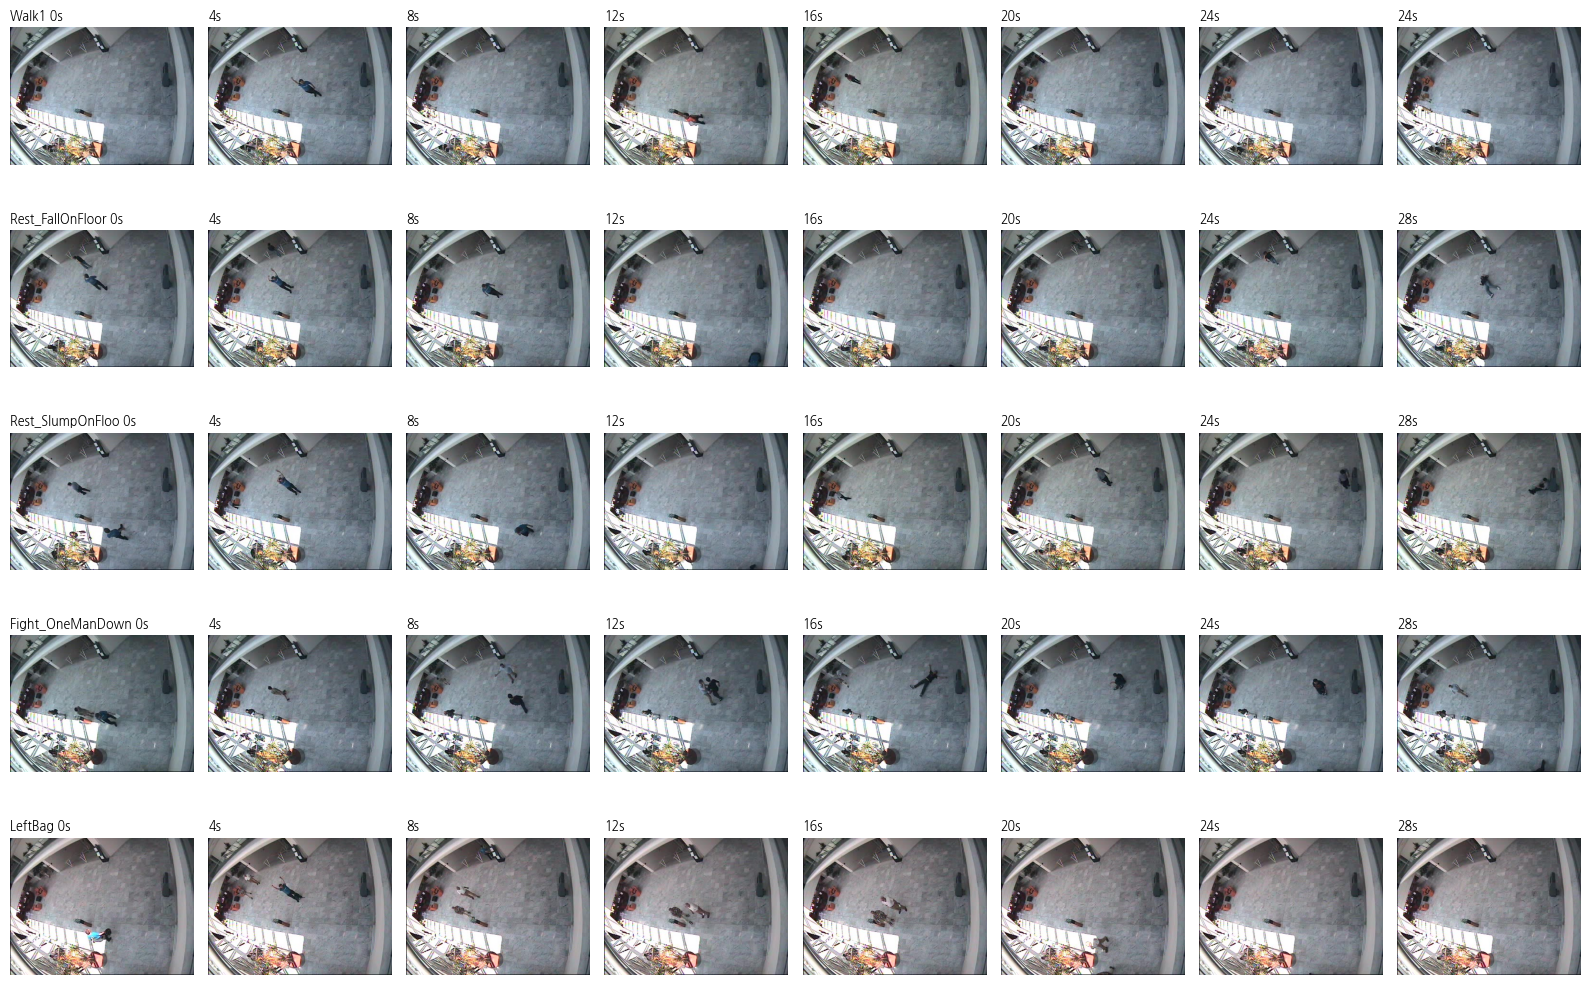

In [5]:
#@title 한눈에 보기 (4초마다 한 장)
from PIL import Image
fig, axes = plt.subplots(len(CLIPS), 8, figsize=(16, 2.1 * len(CLIPS)))
for r, n in enumerate(CLIPS):
    fs = sorted(glob.glob(f"frames/{n}/*.jpg"))
    for c in range(8):
        i = min(len(fs) - 1, c * 8)
        axes[r, c].imshow(Image.open(fs[i])); axes[r, c].axis("off")
        axes[r, c].set_title(f"{n[:16]} {i/2:.0f}s" if c == 0 else f"{i/2:.0f}s", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## 3. 모델 띄우기 (live 모드에서만)
`qev serve`가 TypeSafe System One과 같은 모양의 API를 `localhost:8000`에 띄워요. 처음엔 모델을 받느라 몇 분 걸려요.

In [6]:
#@title 설치와 서버 시작
SERVER_OK = False
if MODE == "live":
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qev[torch] @ git+https://github.com/OmniJev/OneJev.git"], check=True)
    log = open("qev.log", "w")
    srv = subprocess.Popen(["qev", "serve", "--model", MODEL, "--multimodal", "--dtype", "float16", "--port", "8000"], stdout=log, stderr=subprocess.STDOUT)
    for i in range(180):  # 최대 15분
        time.sleep(5)
        try:
            urllib.request.urlopen("http://localhost:8000/v1/models", timeout=3); SERVER_OK = True; break
        except Exception:
            if srv.poll() is not None: break
    print("서버:", "준비됨" if SERVER_OK else "실패 → 기록 재생으로 바꿔요 (qev.log 확인)")
    if not SERVER_OK:
        MODE = "replay"
else:
    print("replay 모드: 서버를 띄우지 않아요")

서버: 준비됨


## 4. 판단 함수 `ask()`
영상은 **사진 묶음 + fps**로 보내요. 질문은 지시문을 영어로 쓰고(Colab ① 팁), 상황 설명은 `state`에 적어요.

In [7]:
QUESTIONS = {
    "scene": ("choice", "What is happening in this CCTV video?", {
        "passing": "people walking or passing through normally",
        "lingering": "people standing, browsing, waiting or sitting calmly",
        "meeting": "people meeting and talking calmly in a group",
        "person_down": "a person has fallen down or is lying or slumped on the floor",
        "fighting": "people fighting, pushing each other, chasing, or running away from a fight",
        "left_object": "a bag or box is left behind on the floor without its owner",
        "empty": "no people are visible"}),
    "down": ("noul", "In this video, is any person lying or slumped on the floor?"),
    "staff": ("noul", "Should a staff member go to this place right now to check on people?"),
    "urgency": ("score", "How urgently should staff respond?", ["no action needed", "keep watching", "check soon", "respond immediately"]),
}
STATE = {"camera": "overhead fisheye CCTV of a building lobby; people look small from above", "video": "<video:1>"}
KO = {"passing": "지나감", "lingering": "머무름", "meeting": "만남", "person_down": "쓰러짐", "fighting": "다툼", "left_object": "물건 방치", "empty": "사람 없음"}

def ask(frames, fps):
    """사진 묶음(동영상) 하나를 판단해요. live면 서버에, replay면 강사 기록에서 찾아요."""
    from qev import Client, Choice, Noul, Score
    from qev.media import data_uri
    q = {k: (Choice(v[1], v[2]) if v[0] == "choice" else Noul(v[1]) if v[0] == "noul" else Score(v[1], v[2])) for k, v in QUESTIONS.items()}
    t0 = time.time()
    r = Client("http://localhost:8000").system_one(state=STATE, questions=q,
        media=[{"type": "video", "frames": [{"data": data_uri(p)} for p in frames], "fps": fps}])
    a = r.answers
    return {"ms": round((time.time() - t0) * 1000), "scene": a["scene"].choice, "scene_probs": a["scene"].probabilities,
            "down": a["down"].noul, "staff": a["staff"].noul, "urgency": a["urgency"].score}
print("ask() 준비 완료 · 질문", list(QUESTIONS))

ask() 준비 완료 · 질문 ['scene', 'down', 'staff', 'urgency']


## 5. 클립 하나를 통째로: 16장을 고르게 뽑아 한 번

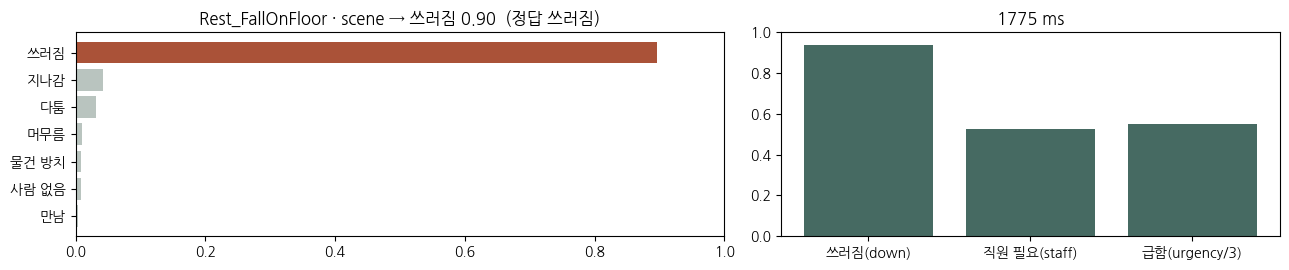

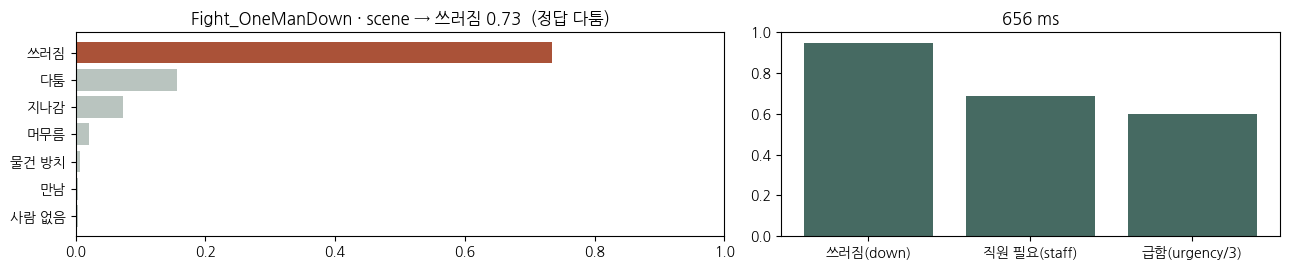

In [8]:
def clip_frames(n, k=16):
    fs = sorted(glob.glob(f"frames/{n}/*.jpg"))
    return [fs[round(i * (len(fs) - 1) / (k - 1))] for i in range(k)], k / (len(fs) / 2)

def show(n, res):
    p = res["scene_probs"]; keys = sorted(p, key=p.get)
    fig, ax = plt.subplots(1, 2, figsize=(13, 2.8), gridspec_kw={"width_ratios": [1.3, 1]})
    ax[0].barh([KO[k] for k in keys], [p[k] for k in keys], color=["#AA5238" if k == res["scene"] else "#B9C4BF" for k in keys])
    ax[0].set_xlim(0, 1); ax[0].set_title(f"{n} · scene → {KO[res['scene']]} {p[res['scene']]:.2f}  (정답 {KO[GT[n]['clip_label']]})")
    ax[1].bar(["쓰러짐(down)", "직원 필요(staff)", "급함(urgency/3)"], [res["down"], res["staff"], res["urgency"] / 3], color="#466A62")
    ax[1].set_ylim(0, 1); ax[1].set_title(f"{res['ms']} ms")
    plt.tight_layout(); plt.show()

for n in ["Rest_FallOnFloor", "Fight_OneManDown"]:
    if MODE == "live":
        frames, fps = clip_frames(n); res = ask(frames, fps)
    else:
        res = REC["clips"][n]; print("(기록 재생: 강사 A4000 · OneJev-0.8B)")
    show(n, res)

## 6. 시간축으로 훑기: 8초 창을 2초씩 밀며
CCTV는 계속 흘러가요. 8초 묶음(1초 1장, 8장)을 2초마다 물어 보면, **언제** 급해졌는지 보여요. 회색 띠가 정답 구간이에요.

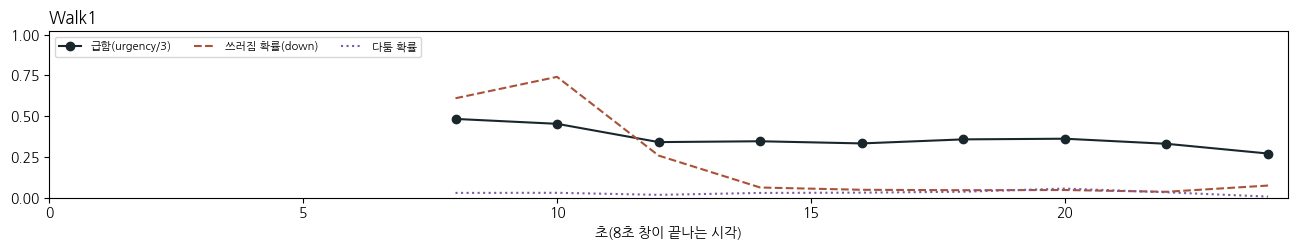

  창 9개 · 판단 중앙값 472 ms


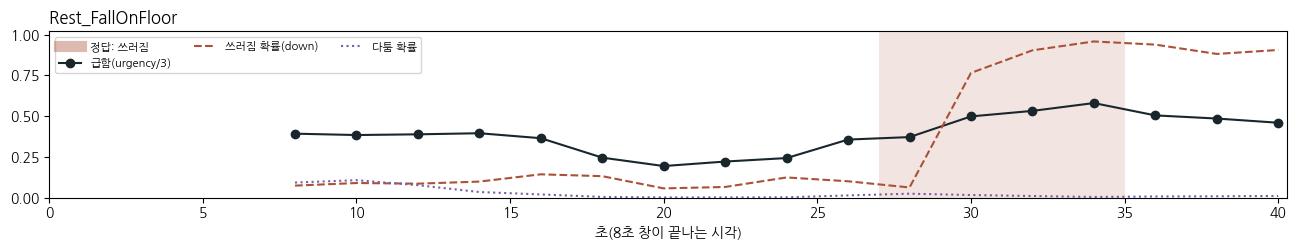

  창 17개 · 판단 중앙값 346 ms


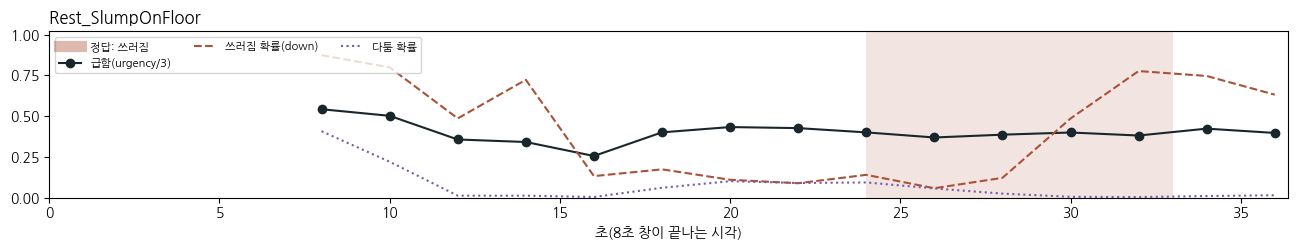

  창 15개 · 판단 중앙값 304 ms


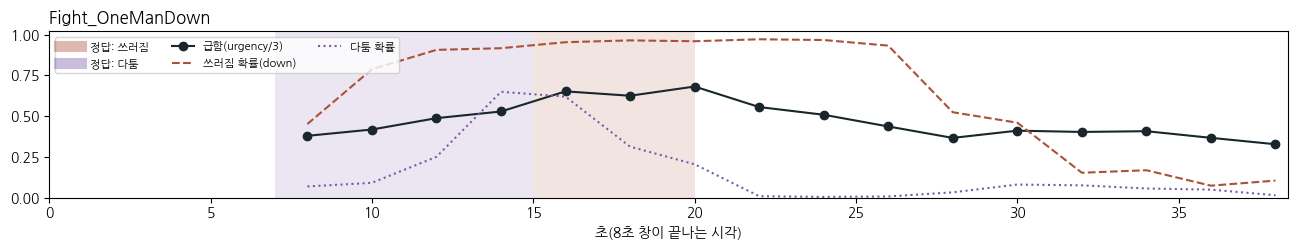

  창 16개 · 판단 중앙값 310 ms


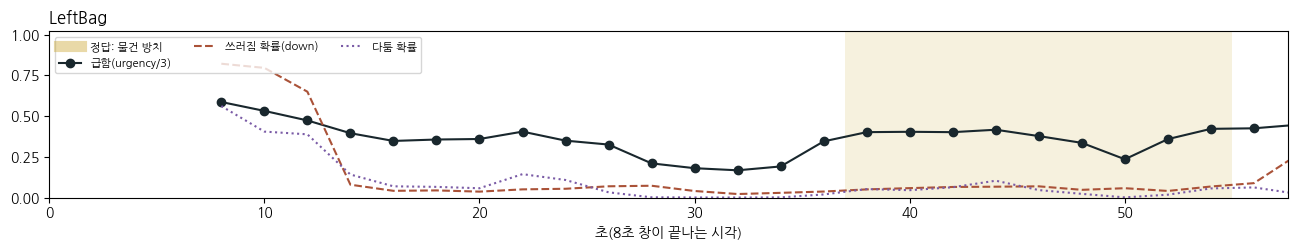

  창 26개 · 판단 중앙값 309 ms


In [9]:
def windows(n):
    fs = sorted(glob.glob(f"frames/{n}/*.jpg")); dur = len(fs) / 2; out = []
    for s in range(0, max(1, int(dur) - 8 + 1), 2):
        w = ask([fs[min(len(fs) - 1, (s + k) * 2)] for k in range(8)], 1.0); w["t0"], w["t1"] = s, s + 8; out.append(w)
    return out

def timeline(n, ws, title=""):
    g = GT[n]; fig, ax = plt.subplots(figsize=(13, 2.6))
    for key, color, label in (("down_s", "#AA5238", "정답: 쓰러짐"), ("fight_s", "#7A5BA6", "정답: 다툼"), ("left_s", "#C9A227", "정답: 물건 방치")):
        for s in g[key]:
            ax.axvspan(s, s + 1, color=color, alpha=0.15, lw=0)
        if g[key]: ax.plot([], [], color=color, alpha=0.4, lw=8, label=label)
    mid = [w["t1"] for w in ws]  # 창이 끝나는 시각 = 판단이 나오는 시각
    ax.plot(mid, [w["urgency"] / 3 for w in ws], "-o", color="#19272D", label="급함(urgency/3)")
    ax.plot(mid, [w["down"] for w in ws], "--", color="#AA5238", label="쓰러짐 확률(down)")
    ax.plot(mid, [w["scene_probs"]["fighting"] for w in ws], ":", color="#7A5BA6", label="다툼 확률")
    ax.set_ylim(0, 1.02); ax.set_xlim(0, g["dur_s"]); ax.set_xlabel("초(8초 창이 끝나는 시각)"); ax.set_title(f"{n} {title}", loc="left")
    ax.legend(loc="upper left", fontsize=8, ncol=3); plt.tight_layout(); plt.show()

for n in CLIPS:
    ws = windows(n) if MODE == "live" else REC["windows"][n]
    timeline(n, ws, "" if MODE == "live" else "(기록 재생 · A4000 OneJev-0.8B)")
    print(f"  창 {len(ws)}개 · 판단 중앙값 {statistics.median(w['ms'] for w in ws):.0f} ms")

## 7. 코드가 정하는 규칙 (smart if)
모델은 확률만 줘요. **언제 사람을 부를지는 우리 코드가** 정해요. 기준값과 "몇 번 연속"을 바꿔 가며 **잡은 쓰러짐 vs 헛알람**을 비교해 보세요(13클립 전체, 강사 기록).

In [10]:
DOWN_AT = 0.9  #@param {type:"slider", min:0.3, max:0.95, step:0.05}
K = 2          #@param {type:"slider", min:1, max:4, step:1}
def alarms(ws):
    hits = [w["down"] >= DOWN_AT for w in ws]   # 쓰러짐 확률이 기준 이상이 K번 연속이면 알람
    return [ws[i]["t1"] for i in range(K - 1, len(ws)) if all(hits[i - j] for j in range(K))]
caught = false = 0
for n in sorted(GT):
    ws = REC["windows"][n] if (MODE == "replay" or n not in CLIPS) else windows(n)
    a, d = alarms(ws), GT[n]["down_s"]
    if d: caught += any(d[0] <= t <= d[-1] + 8 for t in a)
    else: false += bool(a)
    print(f"{n:22s} 정답 {KO[GT[n]['clip_label']]:5s} 쓰러짐 구간 {str(d[0]) + '~' + str(d[-1]) + '초' if d else '-':9s} → 알람 {'없음' if not a else str(a[0]) + '초에 처음'}")
print()
print(f"쓰러짐 {caught}/3 잡음 · 헛알람 {false}/10 (기준 {DOWN_AT} · {K}번 연속)")
print("강사 실측(0.8B): 0.5·2번 → 3/3 잡고 헛알람 5/10, 0.9·2번 → 2/3 잡고 헛알람 0/10. 어느 쪽을 고를지는 '놓치면 얼마나 위험한가'로 정해요.")

Browse1                정답 머무름   쓰러짐 구간 -         → 알람 없음
Browse_WhileWaiting1   정답 머무름   쓰러짐 구간 -         → 알람 없음
Fight_Chase            정답 다툼    쓰러짐 구간 -         → 알람 없음
Fight_OneManDown       정답 다툼    쓰러짐 구간 15~19초    → 알람 14초에 처음
Fight_RunAway1         정답 다툼    쓰러짐 구간 -         → 알람 없음
LeftBag                정답 물건 방치 쓰러짐 구간 -         → 알람 없음
LeftBag_PickedUp       정답 물건 방치 쓰러짐 구간 -         → 알람 없음
Meet_Split_3rdGuy      정답 만남    쓰러짐 구간 -         → 알람 없음
Meet_WalkTogether1     정답 만남    쓰러짐 구간 -         → 알람 없음
Rest_FallOnFloor       정답 쓰러짐   쓰러짐 구간 27~34초    → 알람 34초에 처음
Rest_InChair           정답 머무름   쓰러짐 구간 -         → 알람 없음
Rest_SlumpOnFloor      정답 쓰러짐   쓰러짐 구간 24~32초    → 알람 없음
Walk1                  정답 지나감   쓰러짐 구간 -         → 알람 없음

쓰러짐 2/3 잡음 · 헛알람 0/10 (기준 0.9 · 2번 연속)
강사 실측(0.8B): 0.5·2번 → 3/3 잡고 헛알람 5/10, 0.9·2번 → 2/3 잡고 헛알람 0/10. 어느 쪽을 고를지는 '놓치면 얼마나 위험한가'로 정해요.


## 8. 열세 클립 전체: 강사 기록으로 보기 (A4000 · OneJev 0.8B vs 4B)

In [11]:
#@title 클립 13개 분류표
rows = []
for n in sorted(GT):
    big, small = REC_BIG["clips"][n], REC["clips"].get(n, {})
    rows.append((n, KO[GT[n]["clip_label"]], KO[big["scene"]], big["scene_probs"][big["scene"]], big["down"], big["urgency"], KO.get(small.get("scene"), "-")))
ok_big = sum(r[1] == r[2] for r in rows); ok_small = sum(r[1] == r[6] for r in rows)
print(f"{'클립':22s} {'정답':6s} {'4B 답':8s} {'확률':>5s} {'쓰러짐':>6s} {'급함':>5s}  0.8B 답")
for r in rows:
    print(f"{r[0]:22s} {r[1]:6s} {r[2]:8s} {r[3]:5.2f} {r[4]:6.2f} {r[5]:5.2f}  {r[6]}")
print(f"\n클립 분류 일치: 4B {ok_big}/{len(rows)} · 0.8B {ok_small}/{len(rows)}")
print("판단 지연(8장 묶음): 0.8B 중앙값", statistics.median(w['ms'] for ws in REC['windows'].values() for w in ws), "ms · 4B",
      statistics.median(w['ms'] for ws in REC_BIG['windows'].values() for w in ws), "ms (RTX A4000, 4B는 다른 프로그램과 GPU를 나눠 써서 느림)")

클립                     정답     4B 답        확률    쓰러짐    급함  0.8B 답
Browse1                머무름    지나감       0.89   0.08  1.25  지나감
Browse_WhileWaiting1   머무름    지나감       0.92   0.05  1.21  지나감
Fight_Chase            다툼     다툼        0.37   0.62  1.77  쓰러짐
Fight_OneManDown       다툼     쓰러짐       0.64   0.95  1.80  쓰러짐
Fight_RunAway1         다툼     지나감       0.70   0.08  1.25  다툼
LeftBag                물건 방치  지나감       0.50   0.29  1.87  지나감
LeftBag_PickedUp       물건 방치  지나감       0.59   0.10  1.44  지나감
Meet_Split_3rdGuy      만남     지나감       0.83   0.08  1.23  지나감
Meet_WalkTogether1     만남     지나감       0.87   0.03  1.28  지나감
Rest_FallOnFloor       쓰러짐    쓰러짐       0.66   0.78  1.85  쓰러짐
Rest_InChair           머무름    지나감       0.83   0.40  1.18  지나감
Rest_SlumpOnFloor      쓰러짐    지나감       0.67   0.44  1.53  지나감
Walk1                  지나감    지나감       0.74   0.20  1.40  쓰러짐

클립 분류 일치: 4B 3/13 · 0.8B 2/13
판단 지연(8장 묶음): 0.8B 중앙값 2379.5 ms · 4B 2825 ms (RTX A4000, 4B는 다른 프로그램과 GPU를 나눠 써서 느림)

## 9. 내 질문으로 바꿔 보기 (live 모드)
`QUESTIONS`의 지시문이나 보기를 바꾸고 5장 · 6장을 다시 실행해 보세요. 예) `"staff"`를 `"Is anyone running?"`으로 바꾸기.

## 10. 정리
- 영상도 **사진 묶음 + fps**로 보내면 글처럼 판단해요. 답은 문장이 아니라 **보기마다 확률**이에요.
- 천장 어안 렌즈처럼 사람이 작게 나오는 화면은 어려워요. **틀린 클립을 꼭 같이 보세요.**
- 알람은 확률 한 번이 아니라 **연속 · 기준값 · 사람 확인**을 코드로 엮어서.
- 실제 학교 영상은 개인영상정보예요. 목적 외 이용 · 보관 기간 · 비식별 · IRB를 먼저.

데이터 출처: EC Funded CAVIAR project/IST 2001 37540, http://homepages.inf.ed.ac.uk/rbf/CAVIAR/ (CC BY-SA)